# AI-XRay · 02 — Preprocesamiento y Data Augmentation

**Proyecto Final Independiente** · César Libardo España Salguero

### Objetivo
1. Cargar el manifiesto con split generado en `01_exploracion.ipynb`.
2. Construir los `tf.data.Dataset` de train/val/test con `src/preprocessing.py`.
3. Verificar visualmente el resize a 224×224, el `preprocess_input` de ResNet50 y la augmentation.
4. Confirmar que la API usa **exactamente** el mismo preprocesamiento que el entrenamiento.

In [1]:
%matplotlib inline
import sys
from pathlib import Path

# Este notebook vive en AI-XRay/notebooks/; agregamos AI-XRay/ al path para importar `src`.
PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from src.config import BATCH_SIZE, IMG_SIZE, SPLIT_MANIFEST_PATH
from src.preprocessing import build_augmentation, dataset_from_manifest, preprocess_image_bytes

split = pd.read_csv(SPLIT_MANIFEST_PATH)
split.groupby(["split", "label_name"]).size().unstack()

label_name,NORMAL,PNEUMONIA
split,,
test,146,156
train,701,688
val,153,156


## 1. Datasets de train/val/test

In [2]:
train_ds = dataset_from_manifest(split, "train", batch_size=BATCH_SIZE)
val_ds = dataset_from_manifest(split, "val", batch_size=BATCH_SIZE)
test_ds = dataset_from_manifest(split, "test", batch_size=BATCH_SIZE)

for x, y in train_ds.take(1):
    print("Batch de train -- shape:", x.shape, "dtype:", x.dtype)
    print("Labels de ejemplo:", y.numpy()[:8])
    print("Rango tras preprocess_input (NO es [0,1]):", round(float(x.numpy().min()), 2), "a", round(float(x.numpy().max()), 2))
print("Batches por época -- train:", len(train_ds), "| val:", len(val_ds), "| test:", len(test_ds))

Batch de train -- shape: (32, 224, 224, 3) dtype: <dtype: 'float32'>
Labels de ejemplo: [0. 1. 1. 0. 0. 0. 1. 1.]
Rango tras preprocess_input (NO es [0,1]): -123.68 a 151.06


Batches por época -- train: 44 | val: 10 | test: 10


## 2. Por qué `preprocess_input` y no una normalización 0-1

`resnet50.preprocess_input` convierte RGB→BGR y resta la media por canal de ImageNet — **no** produce
valores en [0, 1]. Usar `img / 255.0` alimentaría a ResNet50 con una distribución distinta a la que vio
en su preentrenamiento y degradaría el transfer learning. La celda anterior lo confirma.

## 3. Verificación visual (antes de entrenar)

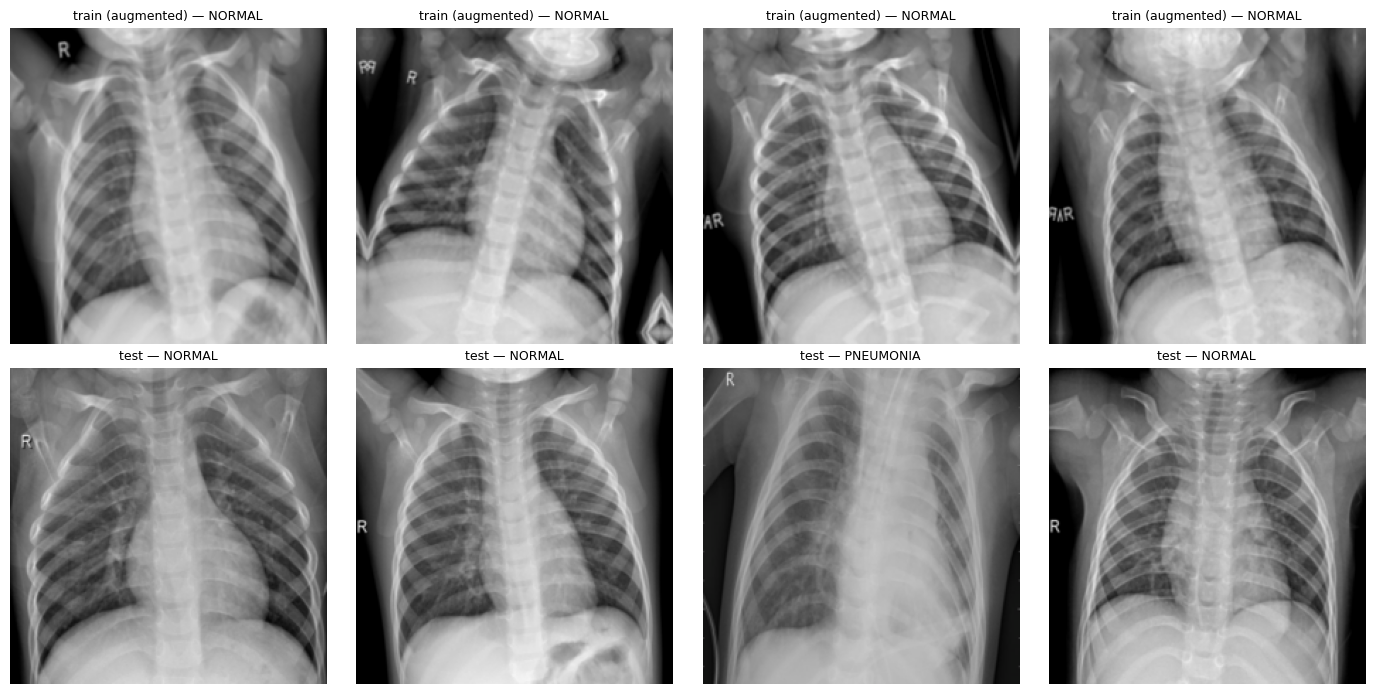

In [3]:
def _denormalize_for_display(img):
    # Revierte preprocess_input (resta de medias BGR de ImageNet) solo para visualizar.
    mean = np.array([103.939, 116.779, 123.68])
    img = img[..., ::-1] + mean[::-1]
    return np.clip(img, 0, 255).astype("uint8")

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
x_tr, y_tr = next(iter(train_ds))
x_te, y_te = next(iter(test_ds))
for i in range(4):
    for row, (x, y, nombre) in enumerate([(x_tr, y_tr, "train (augmented)"), (x_te, y_te, "test")]):
        axes[row][i].imshow(_denormalize_for_display(x.numpy()[i]))
        axes[row][i].set_title(f"{nombre} — {'PNEUMONIA' if y.numpy()[i] == 1 else 'NORMAL'}", fontsize=9)
        axes[row][i].axis("off")
plt.tight_layout()
plt.show()

## 4. ¿Tiene sentido el *flip* horizontal en radiografías de tórax?

El flip horizontal genera una anatomía que prácticamente no existe (corazón a la derecha). Puede actuar
como regularizador, pero también enseña al modelo una variación irreal. No se resuelve opinando: se
convierte en un experimento controlado (**Variante B** en `03_training.ipynb`: idéntica al Run 1 salvo el flip).

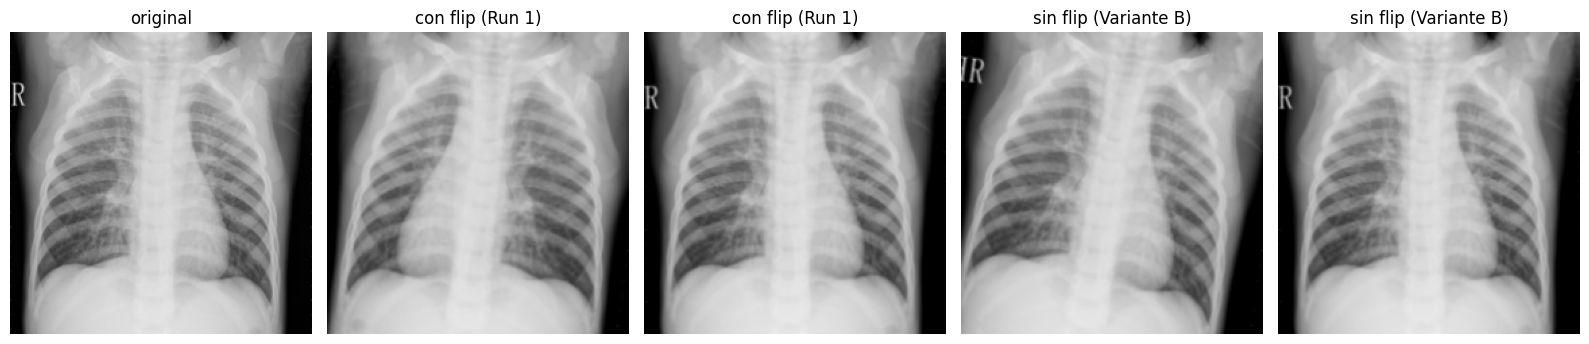

In [4]:
row = split[split["split"] == "train"].iloc[0]
img = tf.image.resize(tf.io.decode_image(tf.io.read_file(row["path"]), channels=3, expand_animations=False), IMG_SIZE, antialias=True)
con_flip = build_augmentation(horizontal_flip=True)
sin_flip = build_augmentation(horizontal_flip=False)

fig, axes = plt.subplots(1, 5, figsize=(16, 3.6))
axes[0].imshow(img.numpy().astype("uint8")); axes[0].set_title("original")
for i in range(1, 3):
    axes[i].imshow(np.clip(con_flip(img, training=True).numpy(), 0, 255).astype("uint8")); axes[i].set_title("con flip (Run 1)")
for i in range(3, 5):
    axes[i].imshow(np.clip(sin_flip(img, training=True).numpy(), 0, 255).astype("uint8")); axes[i].set_title("sin flip (Variante B)")
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()

## 5. Entrenamiento y API usan el mismo preprocesamiento

La versión de clase redimensionaba con `tf.image.resize` al entrenar y con `PIL.resize` en la API
(interpolaciones distintas = *training-serving skew*). Ahora la API llama a `preprocess_image_bytes()`,
que reutiliza las mismas funciones. Lo comprobamos con una imagen de test:

In [5]:
row = split[split["split"] == "test"].iloc[0]
via_api = preprocess_image_bytes(open(row["path"], "rb").read()).numpy()[0]
via_pipeline = next(iter(dataset_from_manifest(split[split["path"] == row["path"]], "test", batch_size=1)))[0].numpy()[0]
print("Diferencia máxima absoluta API vs. pipeline de entrenamiento:", float(np.abs(via_api - via_pipeline).max()))
assert np.allclose(via_api, via_pipeline), "La API y el entrenamiento no preprocesan igual"
print("OK -- mismo preprocesamiento en entrenamiento y en la API.")

Diferencia máxima absoluta API vs. pipeline de entrenamiento: 0.0
OK -- mismo preprocesamiento en entrenamiento y en la API.


Siguiente: `03_training.ipynb`.